<a href="https://colab.research.google.com/github/quanrider/machine-learning/blob/main/buoi1_hocmay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PHẦN 1: BÀI TẬP Ở LỚP**

**1. Yêu cầu 1 & 2: Mô hình đơn biến + Thêm số lượng mẫu và độ nhiễu**

---



--- KẾT QUẢ HỒI QUY TUYẾN TÍNH ĐƠN BIẾN ---
Hệ số chặn (w0 / Intercept): 477.80
Hệ số góc (w1 / Slope): 35.39
MSE: 60070.65
R2 Score: 0.9627


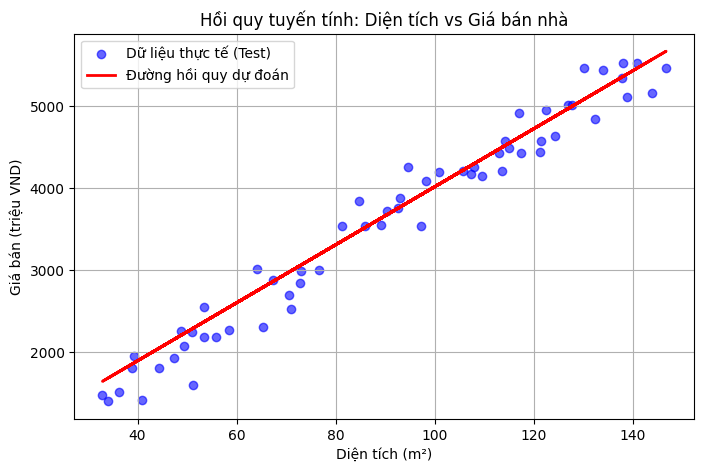

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Cố định seed ngẫu nhiên
np.random.seed(42)

# Sinh 300 mẫu diện tích từ 30m2 đến 150m2
n_samples = 300
area = np.random.uniform(30, 150, (n_samples, 1))

# Giá nhà giả định: Giá cơ sở 500 triệu + 35 triệu/m2 + Nhiễu (std = 300 triệu)
noise = np.random.normal(0, 300, (n_samples, 1))
price = 500 + 35 * area + noise

# 1. Phân chia tập dữ liệu Train / Test (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(area, price, test_size=0.2, random_state=42)

# Khởi tạo và huấn luyện mô hình Linear Regression
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model_lr.predict(X_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"--- KẾT QUẢ HỒI QUY TUYẾN TÍNH ĐƠN BIẾN ---")
print(f"Hệ số chặn (w0 / Intercept): {model_lr.intercept_[0]:.2f}")
print(f"Hệ số góc (w1 / Slope): {model_lr.coef_[0][0]:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R2 Score: {r2:.4f}")

# Trực quan hóa
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Dữ liệu thực tế (Test)')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Đường hồi quy dự đoán')
plt.title("Hồi quy tuyến tính: Diện tích vs Giá bán nhà")
plt.xlabel("Diện tích (m²)")
plt.ylabel("Giá bán (triệu VND)")
plt.legend()
plt.grid(True)
plt.show()

**2. Yêu cầu 3: Thêm các biến đầu vào để nâng cao tính phức tạp (Hồi quy đa biến)**

In [ ]:
import pandas as pd

# Giả lập thêm các thuộc tính:
# - Số phòng ngủ (bedrooms): từ 1 đến 5 phòng
# - Khoảng cách đến trung tâm (distance_to_center_km): từ 1 đến 20 km
# - Số tầng (floors): từ 1 đến 4 tầng
bedrooms = np.random.randint(1, 6, (n_samples, 1))
distance = np.random.uniform(1, 20, (n_samples, 1))
floors = np.random.randint(1, 5, (n_samples, 1))

# Giá nhà chịu ảnh hưởng:
# + 30 triệu/m2, + 150 triệu/phòng ngủ, + 200 triệu/tầng, - 50 triệu/km xa trung tâm + nhiễu
price_multi = (400
               + 30 * area
               + 150 * bedrooms
               + 200 * floors
               - 50 * distance
               + np.random.normal(0, 200, (n_samples, 1)))

# Tạo ma trận đặc trưng X đa biến
X_multi = np.hstack([area, bedrooms, floors, distance])
feature_names = ['Diện tích (m²)', 'Số phòng ngủ', 'Số tầng', 'Khoảng cách đến TT (km)']

# Chia dữ liệu Train / Test
X_tr, X_te, y_tr, y_te = train_test_split(X_multi, price_multi, test_size=0.2, random_state=42)

# Huấn luyện mô hình đa biến
model_multi = LinearRegression()
model_multi.fit(X_tr, y_tr)

# Dự đoán và đánh giá
y_pred_multi = model_multi.predict(X_te)
print("--- KẾT QUẢ HỒI QUY ĐA BIẾN ---")
print(f"Hệ số chặn (Intercept): {model_multi.intercept_[0]:.2f}")
for name, coef in zip(feature_names, model_multi.coef_[0]):
    print(f"Hệ số cho {name}: {coef:.2f}")
print(f"MSE: {mean_squared_error(y_te, y_pred_multi):.2f}")
print(f"R2 Score: {r2_score(y_te, y_pred_multi):.4f}")

--- KẾT QUẢ HỒI QUY ĐA BIẾN ---
Hệ số chặn (Intercept): 429.62
Hệ số cho Diện tích (m²): 29.81
Hệ số cho Số phòng ngủ: 147.15
Hệ số cho Số tầng: 189.35
Hệ số cho Khoảng cách đến TT (km): -47.01
MSE: 43582.94
R2 Score: 0.9647


**Bài 2: Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI (Logistic Regression)**

--- KẾT QUẢ ĐÁNH GIÁ LOGISTIC REGRESSION ---
Độ chính xác (Accuracy): 0.8333

Ma trận nhầm lẫn (Confusion Matrix):
[[23  4]
 [ 6 27]]

Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       0.79      0.85      0.82        27
           1       0.87      0.82      0.84        33

    accuracy                           0.83        60
   macro avg       0.83      0.84      0.83        60
weighted avg       0.84      0.83      0.83        60



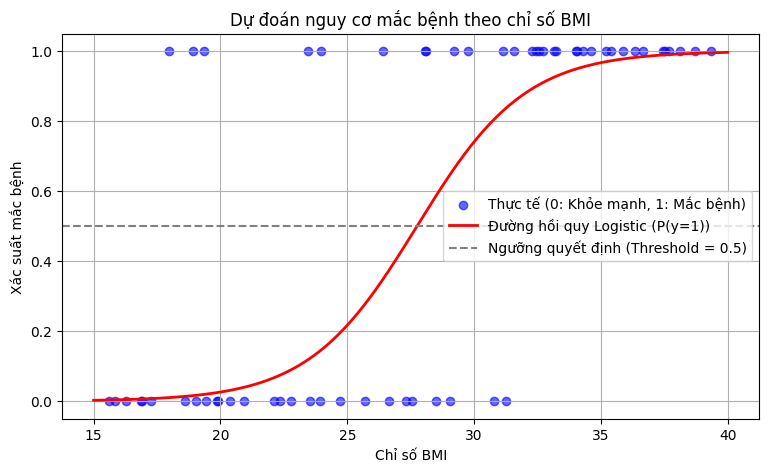

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)

# 1. Tạo dữ liệu mẫu giả lập (300 bệnh nhân có BMI từ 15 đến 40)
n_samples = 300
bmi = np.random.uniform(15, 40, (n_samples, 1))

# Hàm sigmoid để tạo xác suất mắc bệnh thực tế dựa trên BMI (ngưỡng chuyển giao quanh BMI = 27)
z = 0.45 * (bmi - 27)
prob = 1 / (1 + np.exp(-z))
# Gán nhãn 1 (mắc bệnh) hoặc 0 dựa trên phân phối xác suất prob
y = np.random.binomial(1, prob).ravel()

# 2. Chia tập Train / Test
X_train, X_test, y_train, y_test = train_test_split(bmi, y, test_size=0.2, random_state=42)

# 3. Khởi tạo và huấn luyện mô hình Logistic Regression
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

# 4. Dự đoán xác suất và nhãn mắc bệnh trên tập kiểm tra
y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1] # Xác suất lớp 1

# 5. Đánh giá hiệu quả mô hình
print("--- KẾT QUẢ ĐÁNH GIÁ LOGISTIC REGRESSION ---")
print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("\nMa trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))
print("\nBáo cáo phân loại (Classification Report):")
print(classification_report(y_test, y_pred))

# 6. Trực quan hóa dữ liệu và đường hồi quy sigmoid
plt.figure(figsize=(9, 5))
# Vẽ điểm dữ liệu thực tế
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Thực tế (0: Khỏe mạnh, 1: Mắc bệnh)')

# Vẽ đường cong hàm Sigmoid ước lượng của mô hình
X_line = np.linspace(15, 40, 300).reshape(-1, 1)
y_line_prob = log_reg.predict_proba(X_line)[:, 1]
plt.plot(X_line, y_line_prob, color='red', linewidth=2, label='Đường hồi quy Logistic (P(y=1))')

# Đường ngưỡng xác suất 0.5
plt.axhline(0.5, color='gray', linestyle='--', label='Ngưỡng quyết định (Threshold = 0.5)')

plt.title("Dự đoán nguy cơ mắc bệnh theo chỉ số BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.grid(True)
plt.show()

**Bài 3: Hồi quy với một bộ dữ liệu thực tế (Bộ dữ liệu California Housing có sẵn trong sklearn)**

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# 1. Tải bộ dữ liệu thực tế California Housing
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("5 dòng đầu của dữ liệu:")
print(df.head())

X = housing.data
y = housing.target # Giá trị trung bình nhà ở (đơn vị: 100,000$)

# 2. Phân chia tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu (StandardScaler) - Tiền xử lý chuẩn cho hồi quy
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Huấn luyện mô hình
reg_california = LinearRegression()
reg_california.fit(X_train_scaled, y_train)

# 5. Dự đoán và đánh giá
y_pred = reg_california.predict(X_test_scaled)
print("\n--- ĐÁNH GIÁ MÔ HÌNH TRÊN CALIFORNIA HOUSING ---")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

5 dòng đầu của dữ liệu:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

--- ĐÁNH GIÁ MÔ HÌNH TRÊN CALIFORNIA HOUSING ---
Mean Squared Error (MSE): 0.5559
R² Score: 0.5758
